# Heterogeneous Sheaf Neural Networks

Real graphs rarely contain one kind of node and one kind of edge. A bibliographic network links *authors*, *papers*, *venues*, and *terms* through relations such as *writes*, *cites*, and *published-in*. This notebook shows how the repository's **HetSheaf** models (Braithwaite et al., 2024) bring this type information into the sheaf: the restriction map of every edge is predicted from the node features **and** the node and edge types.

### What You Will Learn
* The difference between **heterogeneity** (a schema of typed nodes and relations) and **heterophily** (disagreeing neighbour labels).
* How the repository flattens a typed graph into one homogeneous index space without losing the types.
* The **eight sheaf-predictor families** of HetSheaf, and how each one maps onto the `use_features`, `use_node_types`, `use_edge_types`, and `ensemble` flags.
* A controlled experiment where relation types carry information that features cannot, and an interpretability analysis showing *how* the learned sheaf uses that information.
* How to run the same models on the HGB benchmark datasets.

### Notebook Roadmap
1. **Motivate** typed graphs and the HetSheaf idea.
2. **Formalize** heterogeneous sheaves and the predictor families.
3. **Build** a typed toy graph where relations matter.
4. **Train** feature-only and type-aware sheaf models side by side.
5. **Interpret** the learned restriction maps per relation type, and test them with counterfactual types.
6. **Scale up** to the HGB datasets with the repository pipeline.

No dataset download is needed for the toy sections.

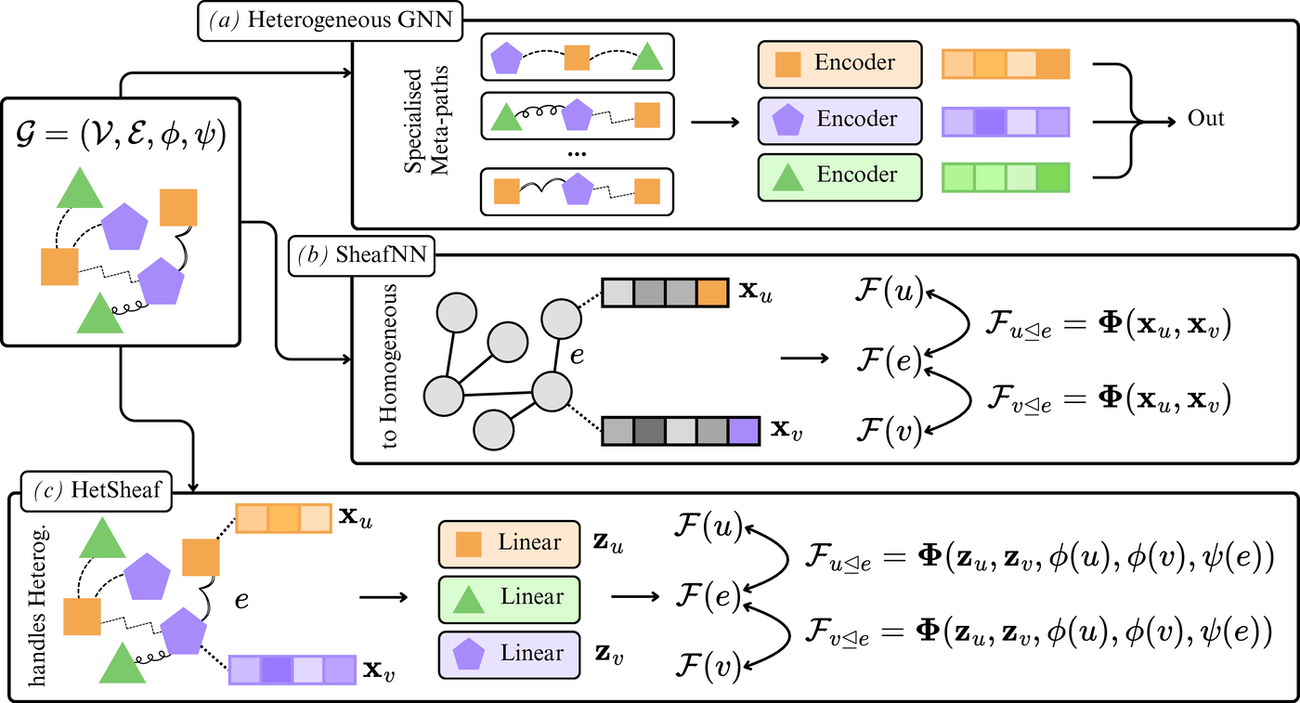

*(a) Conventional heterogeneous GNNs encode types through specialised architectural components such as meta-paths and per-type encoders. (b) A plain SheafNN needs a homogeneous graph, so type information can only enter through the features. (c) HetSheaf projects type-specific features into a shared space and conditions the restriction maps explicitly on the node types phi(.) and the edge type psi(.).*

<sub>Source: Braithwaite et al. (2024), *Heterogeneous Sheaf Neural Networks*, [arXiv:2409.08036](https://arxiv.org/abs/2409.08036), Fig. 1. Reproduced for teaching with attribution (CC BY 4.0).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Heterogeneous Sheaves](#3-heterogeneous-sheaves)
    * [Typed Graphs and Flattening](#typed-graphs)
    * [Type-Conditioned Restriction Maps](#type-conditioned-maps)
    * [The Predictor Families in Code](#predictor-families)
4. [Dataset Pipeline: a Signed, Typed Toy Graph](#4-dataset-pipeline)
5. [Model Construction](#5-model-construction)
6. [Training Pipeline](#6-training-pipeline)
7. [Interpreting the Learned Sheaf](#7-interpretation)
    * [Restriction Maps per Relation Type](#maps-per-relation)
    * [Counterfactual Relation Types](#counterfactual-types)
8. [Scaling Up: HGB Datasets](#8-hgb)
9. [Configuration, Reproducibility, and Exercises](#9-exercises)

<a id="1-introduction"></a>
# 1. Introduction

Two words are easy to confuse:
* **Heterogeneity** is about the *schema*. Nodes and edges come in different types (an author is not a paper; *writes* is not *cites*).
* **Heterophily** is about the *labels*. Connected nodes tend to belong to different classes.

Neither implies the other. A heterogeneous graph can be homophilic, and a homogeneous graph can be strongly heterophilic. They interact, though: the *type* of a relation often tells us whether its endpoints should agree. A *co-author* edge suggests the same research area, while an *opposes* edge in a signed social network suggests opposite opinions.

Classical heterogeneous GNNs, such as R-GCN, HAN, and meta-path models, add type-specific architecture. **HetSheaf** takes a different route. It keeps a single sheaf diffusion model and moves the type information into the **geometry**. Every edge receives restriction maps predicted from its endpoints' features *and* types, so different relations can transport features differently: preserving them, rotating them, or flipping them.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

Use the repository's Python 3.13 environment (`uv sync`) and run the notebook top to bottom from a fresh kernel. Everything below runs on CPU in well under a minute.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import copy
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# =====================================================================
# 2. Core Scientific Libraries
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.data import Data

# =====================================================================
# 3. Reproducibility
# =====================================================================
warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)  # noqa: NPY002
    torch.manual_seed(seed)


set_seed(SEED)
torch.set_num_threads(1)  # small graphs: avoid thread overhead and nondeterminism

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

# =====================================================================
# 4. Repository-Specific Modules
# =====================================================================
from torch_geometric.utils import to_undirected

from hetsheaf_mpnn.nsd.nsd_layers import DiagonalHetNSDConv
from hetsheaf_mpnn.nsd.nsd_model import HetNSDModel, HetNSDVariant

print("Loaded HetNSDModel and its layers from hetsheaf_mpnn.")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0
Loaded HetNSDModel and its layers from hetsheaf_mpnn.


<a id="3-heterogeneous-sheaves"></a>
# 3. Heterogeneous Sheaves

<a id="typed-graphs"></a>
### 3.1 Typed Graphs and Flattening

A heterogeneous graph is a tuple $\mathcal{G} = (\mathcal{V}, \mathcal{E}, \phi, \psi)$, where $\phi: \mathcal{V} \to \mathcal{T}_V$ assigns a **node type** and $\psi: \mathcal{E} \to \mathcal{T}_E$ assigns an **edge (relation) type**. PyTorch Geometric stores such graphs as `HeteroData`, one feature matrix per node type and one `edge_index` per relation.

Sheaf diffusion needs a single node index space, because the sheaf Laplacian is one $nd \times nd$ operator. The repository therefore calls PyG's `to_homogeneous()` (see `src/exp/datasets/hgb.py`), which:
* concatenates all nodes into one index range and records `node_type` $\in \{0, \dots, |\mathcal{T}_V| - 1\}$ for every node;
* concatenates all relations into one `edge_index` and records `edge_type` for every edge;
* zero-pads node features of different widths to a common width, so that one shared encoder can lift them to stalks.

Nothing is lost in this flattening: `node_type` and `edge_type` travel with the data and are passed to every het model as `model(x, edge_index, node_types, edge_types)`.

<a id="type-conditioned-maps"></a>
### 3.2 Type-Conditioned Restriction Maps

In Neural Sheaf Diffusion, the map of the incidence $u \trianglelefteq e$ for $e = (u, v)$ is predicted from the endpoint features, $\mathcal{F}_{u \trianglelefteq e} = \Phi(\mathbf{x}_u \,\|\, \mathbf{x}_v)$. HetSheaf conditions the predictor on the types as well:

$$\mathcal{F}_{u \trianglelefteq e} = \Phi\big(\mathbf{z}_u,\ \mathbf{z}_v,\ \phi(u),\ \phi(v),\ \psi(e)\big),$$

where $\mathbf{z}_u$ is the lifted feature of $u$ and the types enter as one-hot vectors. The diffusion operator is unchanged: it is still the normalized sheaf Laplacian, and every NSD-style family in the repository (NSD, NSP, SheafAttn, NLSD, SheafAdj, DNSD, ...) has a `Het*` mirror built this way. The paper studies eight choices of which inputs $\Phi$ sees:

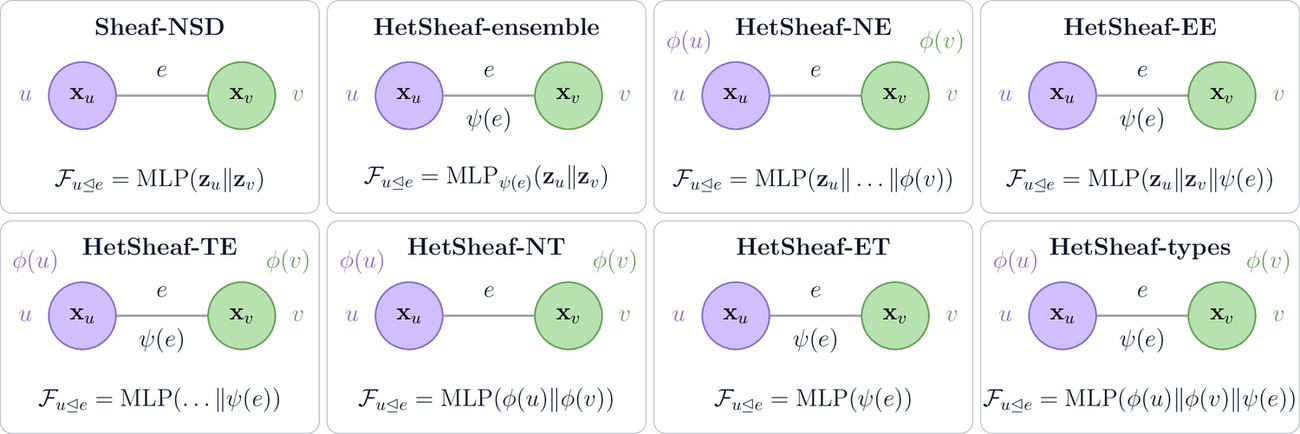

*The heterogeneous sheaf predictors. For an edge e = (u, v), phi(u) and phi(v) are node types, psi(e) is the edge type, x_u and x_v are node features (z after the shared projection), || is concatenation, and MLP_psi(e) denotes a separate MLP for each edge type.*

<sub>Source: Braithwaite et al. (2024), *Heterogeneous Sheaf Neural Networks*, [arXiv:2409.08036](https://arxiv.org/abs/2409.08036), Fig. 2. Reproduced for teaching with attribution (CC BY 4.0).</sub>

<a id="predictor-families"></a>
### 3.3 The Predictor Families in Code

In the repository, the predictor is chosen with four boolean flags on every het layer and model:

| Paper name | Inputs of $\Phi$ | `use_features` | `use_node_types` | `use_edge_types` | `ensemble` |
|---|---|:-:|:-:|:-:|:-:|
| Sheaf-NSD | $\mathbf{z}_u \| \mathbf{z}_v$ | ✓ | | | |
| HetSheaf-ensemble | $\mathbf{z}_u \| \mathbf{z}_v$, one MLP per $\psi(e)$ | ✓ | | | ✓ |
| HetSheaf-NE | $\mathbf{z}_u \| \mathbf{z}_v \| \phi(u) \| \phi(v)$ | ✓ | ✓ | | |
| HetSheaf-EE | $\mathbf{z}_u \| \mathbf{z}_v \| \psi(e)$ | ✓ | | ✓ | |
| HetSheaf-TE | $\mathbf{z}_u \| \mathbf{z}_v \| \phi(u) \| \phi(v) \| \psi(e)$ | ✓ | ✓ | ✓ | |
| HetSheaf-NT | $\phi(u) \| \phi(v)$ | | ✓ | | |
| HetSheaf-ET | $\psi(e)$ | | | ✓ | |
| HetSheaf-types | $\phi(u) \| \phi(v) \| \psi(e)$ | | ✓ | ✓ | |

The cell below instantiates a diagonal het layer for each family and prints the width of the MLP input it builds. This is a quick way to check that the flags do what the table says. In ensemble mode the edge type selects *which* MLP runs instead of being concatenated, so it does not add input width.

In [2]:
# =====================================================================
# MLP input width of every predictor family (d=2, hidden=8 -> z has 16 dims)
# =====================================================================
FAMILIES = {
    "Sheaf-NSD": dict(use_features=True),
    "HetSheaf-ensemble": dict(use_features=True, ensemble=True),
    "HetSheaf-NE": dict(use_features=True, use_node_types=True),
    "HetSheaf-EE": dict(use_features=True, use_edge_types=True),
    "HetSheaf-TE": dict(use_features=True, use_node_types=True, use_edge_types=True),
    "HetSheaf-NT": dict(use_features=False, use_node_types=True),
    "HetSheaf-ET": dict(use_features=False, use_edge_types=True),
    "HetSheaf-types": dict(
        use_features=False, use_node_types=True, use_edge_types=True
    ),
}
NUM_NODE_TYPES, NUM_EDGE_TYPES = 2, 2

print(f"{'family':<19}{'MLP input':>10}{'generators':>12}{'map params':>12}")
for name, flags in FAMILIES.items():
    layer = DiagonalHetNSDConv(
        stalk_dim=2,
        in_channels=8,
        hidden_dim=8,
        num_node_types=NUM_NODE_TYPES,
        num_edge_types=NUM_EDGE_TYPES,
        use_features=flags.get("use_features", True),
        use_node_types=flags.get("use_node_types", False),
        use_edge_types=flags.get("use_edge_types", False),
        ensemble=flags.get("ensemble", False),
    )
    gens = (
        layer.map_generators
        if hasattr(layer, "map_generators")
        else [layer.map_generator]
    )
    n_params = sum(p.numel() for g in gens for p in g.parameters())
    print(f"{name:<19}{layer._mlp_input_dim():>10}{len(gens):>12}{n_params:>12}")

family              MLP input  generators  map params
Sheaf-NSD                  32           1         282
HetSheaf-ensemble          32           2         564
HetSheaf-NE                36           1         314
HetSheaf-EE                34           1         298
HetSheaf-TE                38           1         330
HetSheaf-NT                 4           1          58
HetSheaf-ET                 2           1          42
HetSheaf-types              6           1          74


<a id="4-dataset-pipeline"></a>
# 4. Dataset Pipeline: a Signed, Typed Toy Graph

To see what types can add, we need a task where they carry information that features do not. We build a small **signed network**, the kind used to model trust and distrust between users:
* 120 nodes with a binary label $y_u$ and a **node type** ("author" or "paper") drawn **independently** of the label, so the node type is a pure distractor;
* a sparse random graph whose edges are typed by the **relation** between their endpoints: *endorses* ($\psi = 0$) when the labels agree and *opposes* ($\psi = 1$) when they differ;
* weak, noisy features: each node sees its own label only through a small offset buried in Gaussian noise.

Because the edges are drawn at random, about half of them join different labels, an edge homophily near 0.5. Notebook 0 showed that this is the worst regime for neighbour averaging: positive and negative evidence cancel. A model that knows the relation type can resolve this by *flipping* the messages that arrive along *opposes* edges.

The labels never enter the model directly. The relation types encode label *agreement*, which is exactly the kind of schema knowledge a heterogeneous graph provides, while the labels of test nodes stay hidden.

In [3]:
def random_splits(n: int, train: float = 0.4, val: float = 0.2, seed: int = SEED):
    """Disjoint boolean train/val/test masks over n nodes."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_train, n_val = int(train * n), int(val * n)
    masks = [torch.zeros(n, dtype=torch.bool) for _ in range(3)]
    masks[0][perm[:n_train]] = True
    masks[1][perm[n_train : n_train + n_val]] = True
    masks[2][perm[n_train + n_val :]] = True
    return masks


# =====================================================================
# Build the signed, typed toy graph
# =====================================================================
set_seed(SEED)
n = 120
y = torch.randint(0, 2, (n,))
node_types = torch.randint(0, 2, (n,))  # "author"=0 / "paper"=1, independent of y

# Sparse Erdos-Renyi graph, stored in both directions.
p_edge = 4.0 / n
upper = torch.triu(torch.rand(n, n) < p_edge, diagonal=1)
edge_index = to_undirected(upper.nonzero().t(), num_nodes=n)
src, dst = edge_index
edge_types = (y[src] != y[dst]).long()  # 0 = endorses (agree), 1 = opposes

# Weak label signal in 4 noisy feature dimensions.
signal = 0.6 * (2 * y.float() - 1)
x = torch.randn(n, 4)
x[:, 0] += signal

train_mask, val_mask, test_mask = random_splits(n)
data = Data(
    x=x,
    y=y,
    edge_index=edge_index,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask,
    node_type=node_types,
    edge_type=edge_types,
)

print("--- Typed toy graph ---")
print(data)
print(f"Undirected edges:      {edge_index.size(1) // 2}")
print(f"Edge homophily:        {(y[src] == y[dst]).float().mean():.3f}")
print(f"'opposes' edges:       {edge_types.float().mean():.3f} of all edges")
print(
    f"Node type vs label correlation: {torch.corrcoef(torch.stack([node_types.float(), y.float()]))[0, 1]:+.3f}"
)
print(
    f"Split sizes (train/val/test): {[int(m.sum()) for m in (train_mask, val_mask, test_mask)]}"
)

--- Typed toy graph ---
Data(x=[120, 4], edge_index=[2, 460], y=[120], train_mask=[120], val_mask=[120], test_mask=[120], node_type=[120], edge_type=[460])
Undirected edges:      230
Edge homophily:        0.513
'opposes' edges:       0.487 of all edges
Node type vs label correlation: +0.145
Split sizes (train/val/test): [48, 24, 48]


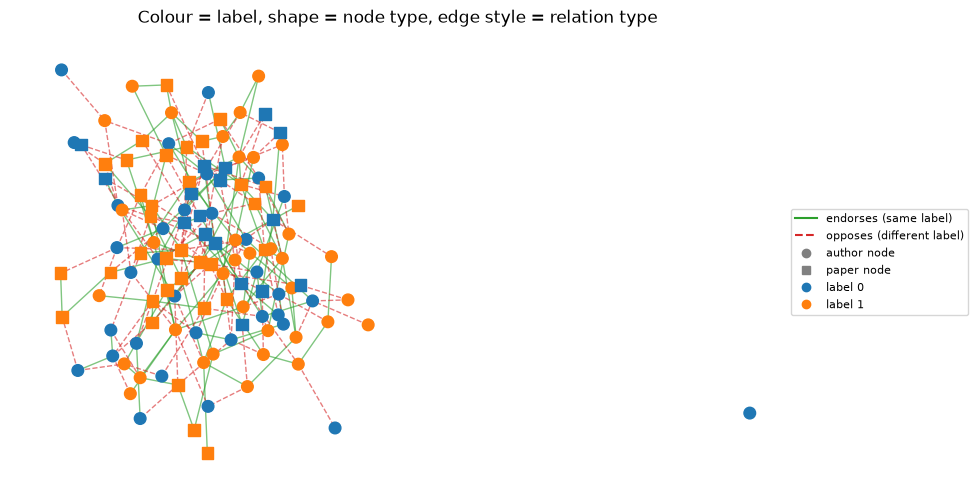

In [4]:
# =====================================================================
# Draw the typed graph
# =====================================================================
import networkx as nx

G = nx.Graph()
G.add_nodes_from(range(n))
G.add_edges_from(edge_index[:, src < dst].t().tolist())
pos = nx.spring_layout(G, seed=3)

fig, ax = plt.subplots(figsize=(10, 6))
for rel, style, colour, name in [
    (0, "solid", "tab:green", "endorses"),
    (1, "dashed", "tab:red", "opposes"),
]:
    mask = (edge_types == rel) & (src < dst)
    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=edge_index[:, mask].t().tolist(),
        style=style,
        edge_color=colour,
        alpha=0.6,
        ax=ax,
        label=name,
    )
for t, marker in [(0, "o"), (1, "s")]:
    nodes = (node_types == t).nonzero().flatten().tolist()
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=nodes,
        node_shape=marker,
        node_size=70,
        ax=ax,
        node_color=["tab:blue" if y[u] == 0 else "tab:orange" for u in nodes],
    )

# Neutral proxy artists, so the legend does not tie a shape to a label colour.
from matplotlib.lines import Line2D

handles = [
    Line2D([], [], color="tab:green", label="endorses (same label)"),
    Line2D([], [], color="tab:red", ls="--", label="opposes (different label)"),
    Line2D([], [], marker="o", ls="", color="gray", label="author node"),
    Line2D([], [], marker="s", ls="", color="gray", label="paper node"),
    Line2D([], [], marker="o", ls="", color="tab:blue", label="label 0"),
    Line2D([], [], marker="o", ls="", color="tab:orange", label="label 1"),
]
ax.set_title("Colour = label, shape = node type, edge style = relation type")
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)
ax.axis("off")
plt.show()

<a id="5-model-construction"></a>
# 5. Model Construction

We compare four predictor families on the same `HetNSDModel` backbone with diagonal maps ($d = 2$):
1. **Sheaf-NSD** (features only): the plain sheaf baseline;
2. **HetSheaf-NE** (+ node types): adds a type that is irrelevant by construction;
3. **HetSheaf-EE** (+ edge types): adds the relation;
4. **HetSheaf-types** (types only): no features in $\Phi$ at all.

Only the restriction-map predictor changes. The encoder, the diffusion, and the decoder are identical across the four models.

In [5]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Model factory: same backbone, different predictor inputs
# =====================================================================
MODEL_FAMILIES = {
    "Sheaf-NSD (features)": dict(use_features=True),
    "HetSheaf-NE (+node types)": dict(use_features=True, use_node_types=True),
    "HetSheaf-EE (+edge types)": dict(use_features=True, use_edge_types=True),
    "HetSheaf-types (types only)": dict(
        use_features=False, use_node_types=True, use_edge_types=True
    ),
}


def make_model(flags: dict[str, bool]):
    return HetNSDModel(
        in_channels=data.num_node_features,
        out_channels=2,
        stalk_dim=2,
        hidden_dim=8,
        num_layers=2,
        variant=HetNSDVariant.DIAGONAL,
        num_node_types=2,
        num_edge_types=2,
        input_dropout=0.0,
        dropout=0.0,
        use_features=flags.get("use_features", True),
        use_node_types=flags.get("use_node_types", False),
        use_edge_types=flags.get("use_edge_types", False),
        ensemble=flags.get("ensemble", False),
    )


def predictor(model, nt=None, et=None):
    nt = data.node_type if nt is None else nt
    et = data.edge_type if et is None else et
    return lambda: model(data.x, data.edge_index, node_types=nt, edge_types=et)


demo = make_model(MODEL_FAMILIES["HetSheaf-EE (+edge types)"])
with torch.no_grad():
    logits = predictor(demo)()
print(f"Logits: {tuple(logits.shape)} | finite: {torch.isfinite(logits).all().item()}")
print(f"Trainable parameters: {sum(p.numel() for p in demo.parameters()):,}")
print(
    f"First layer: {type(demo.layers[0]).__name__}, MLP input width {demo.layers[0]._mlp_input_dim()}"
)

Logits: (120, 2) | finite: True
Trainable parameters: 848
First layer: DiagonalHetNSDConv, MLP input width 34


<a id="6-training-pipeline"></a>
# 6. Training Pipeline

Every model is trained with Adam on the masked cross-entropy of the training nodes. We keep the state with the lowest validation loss and evaluate it once on the test nodes. Each family runs with three seeds, since a single toy run is too noisy to compare models.

--- Test accuracy (3 seeds) ---
Sheaf-NSD (features)          0.764 +/- 0.010
HetSheaf-NE (+node types)     0.729 +/- 0.051
HetSheaf-EE (+edge types)     0.833 +/- 0.059
HetSheaf-types (types only)   0.903 +/- 0.064


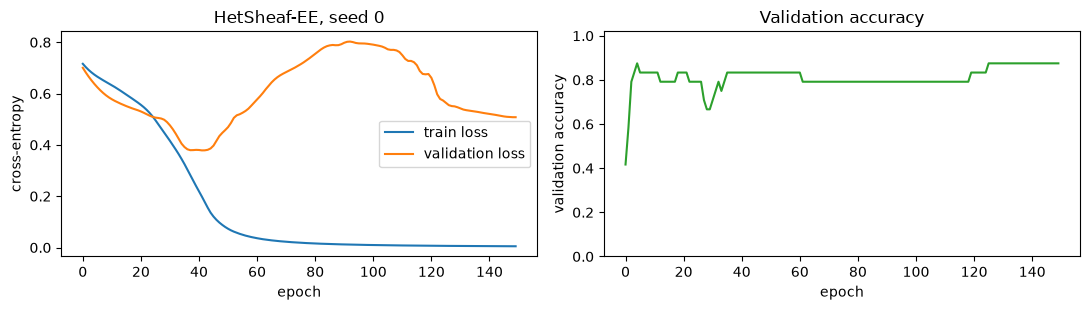

In [6]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)


# =====================================================================
# Masked training with validation-based model selection
# =====================================================================
def accuracy(logits: torch.Tensor, y: torch.Tensor, mask: torch.Tensor) -> float:
    return (logits[mask].argmax(-1) == y[mask]).float().mean().item()


def train_model(
    model, predict, data, epochs=150, lr=0.01, weight_decay=5e-4, extra_loss=None
):
    """Adam on masked cross-entropy; restores the state with the lowest validation loss.

    Args:
        model: the network to optimize.
        predict: zero-argument callable returning logits [N, C] for the whole graph.
        data: PyG Data with y, train_mask, val_mask, test_mask.
        epochs: number of full-batch optimization steps.
        lr: Adam learning rate.
        weight_decay: Adam L2 penalty.
        extra_loss: optional callable(epoch) -> scalar added to the loss (e.g. a KL term).

    Returns:
        (history, test_accuracy) where history holds one dict per epoch.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best_val, best_state = [], float("inf"), None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = predict()
        loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
        if extra_loss is not None:
            loss = loss + extra_loss(epoch)
        assert torch.isfinite(loss), "non-finite training loss"
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_logits = predict()
            val_loss = F.cross_entropy(
                val_logits[data.val_mask], data.y[data.val_mask]
            ).item()
        history.append(
            {
                "train_loss": loss.item(),
                "val_loss": val_loss,
                "val_acc": accuracy(val_logits, data.y, data.val_mask),
            }
        )
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())

    assert best_state is not None, "No finite validation score; check epochs and loss"
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        test_acc = accuracy(predict(), data.y, data.test_mask)
    return history, test_acc


def plot_history(history, title):
    """Training/validation curves of one run."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].plot([h["train_loss"] for h in history], label="train loss")
    axes[0].plot([h["val_loss"] for h in history], label="validation loss")
    axes[0].set(xlabel="epoch", ylabel="cross-entropy", title=title)
    axes[0].legend()
    axes[1].plot([h["val_acc"] for h in history], color="tab:green")
    axes[1].set(
        xlabel="epoch",
        ylabel="validation accuracy",
        ylim=(0, 1.02),
        title="Validation accuracy",
    )
    plt.tight_layout()
    plt.show()


# =====================================================================
# Train every family with three seeds
# =====================================================================
results, trained = {}, {}
for name, flags in MODEL_FAMILIES.items():
    accs = []
    for seed in (0, 1, 2):
        set_seed(seed)
        model = make_model(flags)
        history, test_acc = train_model(model, predictor(model), data, epochs=150)
        accs.append(test_acc)
        if seed == 0:
            trained[name] = (model, history)
    results[name] = accs

print("--- Test accuracy (3 seeds) ---")
for name, accs in results.items():
    print(f"{name:<29} {np.mean(accs):.3f} +/- {np.std(accs):.3f}")
plot_history(trained["HetSheaf-EE (+edge types)"][1], "HetSheaf-EE, seed 0")

**Reading the table.** The features alone are weak, and averaging over neighbourhoods that are half agreeing and half disagreeing cancels much of the evidence. Adding the (irrelevant) node type does not help. Once the relation type reaches the restriction-map predictor, the model can transport the two relations differently, and accuracy improves clearly. The "types only" model shows that, on this task, the relation alone is enough to set up the right geometry. The standard deviations are large because the test set has fewer than 50 nodes: compare the families over more seeds before trusting small gaps.

<a id="7-interpretation"></a>
# 7. Interpreting the Learned Sheaf

<a id="maps-per-relation"></a>
### 7.1 Restriction Maps per Relation Type

What did the type-aware model learn? For a diagonal sheaf, each incidence has a vector $\mathbf{w}_{u \trianglelefteq e} \in \mathbb{R}^d$, and the transport between the two endpoints of $e = (u, v)$ is the element-wise product $\mathbf{w}_{v \trianglelefteq e} \odot \mathbf{w}_{u \trianglelefteq e}$. The layer returns it as `cross_map` from `get_map_products`. We summarize every edge by the **transport alignment**

$$a_e = \frac{\langle \mathbf{w}_{v \trianglelefteq e}, \mathbf{w}_{u \trianglelefteq e}\rangle}{\|\mathbf{w}_{v \trianglelefteq e}\|\,\|\mathbf{w}_{u \trianglelefteq e}\|} \in [-1, 1].$$

$a_e > 0$ means features are carried over with their sign (smoothing), and $a_e < 0$ means they are **flipped** before the comparison. The sheaf intuition predicts positive alignment on *endorses* edges and negative alignment on *opposes* edges.

Sheaf-NSD (features)         endorses: mean alignment +0.389
Sheaf-NSD (features)          opposes: mean alignment +0.313
HetSheaf-EE (+edge types)    endorses: mean alignment +0.902
HetSheaf-EE (+edge types)     opposes: mean alignment -0.037


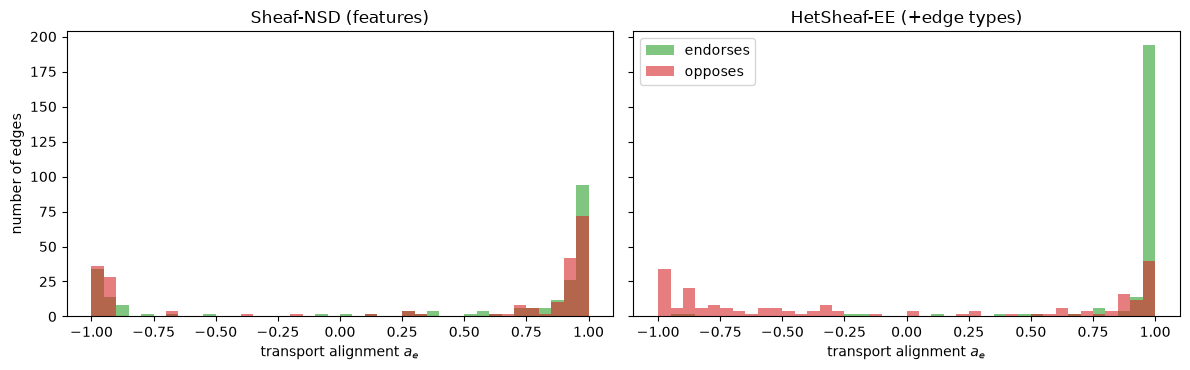

In [7]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)


# =====================================================================
# Transport alignment of the first layer, split by relation type
# =====================================================================
def diagonal_alignment(model):
    assert isinstance(data.edge_index, torch.Tensor)
    layer = model.layers[0]
    with torch.no_grad():
        x_feat = model.encoder(data.x)  # HetNSDModel lifts with a plain linear encoder
        self_dst, cross = layer.get_map_products(
            x_feat, data.edge_index, data.node_type, data.edge_type
        )
        self_src, _ = layer.get_map_products(
            x_feat, data.edge_index.flip(0), data.node_type, data.edge_type
        )
    return (
        cross.sum(-1) / (self_dst.sum(-1) * self_src.sum(-1)).clamp_min(1e-12).sqrt()
    ).numpy()


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
bins = np.linspace(-1, 1, 41)
for ax, name in zip(
    axes, ["Sheaf-NSD (features)", "HetSheaf-EE (+edge types)"], strict=True
):
    align = diagonal_alignment(trained[name][0])
    for rel, colour, label in [(0, "tab:green", "endorses"), (1, "tab:red", "opposes")]:
        ax.hist(
            align[data.edge_type.numpy() == rel],
            bins=bins,
            alpha=0.6,
            color=colour,
            label=label,
        )
        print(
            f"{name:<27} {label:>9}: mean alignment {align[data.edge_type.numpy() == rel].mean():+.3f}"
        )
    ax.set(title=name, xlabel="transport alignment $a_e$")
axes[0].set_ylabel("number of edges")
axes[1].legend()
plt.tight_layout()
plt.show()

The feature-only model cannot tell the two relations apart: both relations show the *same* mixture of preserving ($a_e pprox 1$) and flipping ($a_e pprox -1$) transports, chosen from features alone. The type-aware model separates them. Practically every *endorses* edge keeps an alignment close to $+1$, while the *opposes* edges spread out: a large group is **flipped** to $a_e pprox -1$, and others are weakened. Both outcomes stop a disagreeing neighbour from pulling a node towards the wrong class, and the flipped edges are exactly the *signed* sheaf of notebook 0 (Section 12.4), here learned from data. This is the mechanism by which a sheaf turns a "half-disagreeing" neighbourhood into consistent evidence.

<a id="counterfactual-types"></a>
### 7.2 Counterfactual Relation Types

Alignment shows what the maps *look like*. A counterfactual test shows what the predictions *depend on*. We feed the trained model the same graph with altered relation types and measure test accuracy:
* **true types:** the graph as trained;
* **all endorses:** every edge claims agreement;
* **swapped:** every relation is inverted.

If the model relies on the relation semantics, removing or swapping them should send accuracy back towards chance, because the learned transports no longer match the actual agreement pattern.

In [8]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Counterfactual edge types at test time (trained HetSheaf-EE, seed 0)
# =====================================================================
model = trained["HetSheaf-EE (+edge types)"][0].eval()
scenarios = {
    "true types": data.edge_type,
    "all endorses": torch.zeros_like(data.edge_type),
    "swapped": 1 - data.edge_type,
}
print("--- Test accuracy under counterfactual relation types ---")
for label, et in scenarios.items():
    with torch.no_grad():
        acc = accuracy(predictor(model, et=et)(), data.y, data.test_mask)
    print(f"{label:<14} {acc:.3f}")

--- Test accuracy under counterfactual relation types ---
true types     0.875
all endorses   0.562
swapped        0.542


The drop from *true* to *swapped* types measures how much the decisions rest on the relation semantics, rather than on features or graph structure alone. The same test on a real dataset, for example permuting the edge types of DBLP, is a useful sanity check that a het model actually uses its type inputs.

### 7.3 Per-Relation Generators (Ensemble Mode)

With `ensemble=True`, each relation type gets its **own** generator MLP (the HetSheaf-ensemble family). Instead of conditioning one network on a one-hot type, the parameters themselves are split by relation, in the spirit of R-GCN but still producing sheaf maps. It costs one generator per relation, as the table in Section 3.3 showed, and is useful when relations need very different geometries.

In [9]:
# =====================================================================
# Ensemble mode: one restriction-map generator per relation type
# =====================================================================
set_seed(0)
ens = make_model(dict(use_features=True, ensemble=True))
history, test_acc = train_model(ens, predictor(ens), data, epochs=150)
print(f"Generators in layer 0: {len(ens.layers[0].map_generators)}")
print(f"Test accuracy (HetSheaf-ensemble, seed 0): {test_acc:.3f}")

Generators in layer 0: 2
Test accuracy (HetSheaf-ensemble, seed 0): 0.896


<a id="8-hgb"></a>
# 8. Scaling Up: HGB Datasets

The same models run on the **Heterogeneous Graph Benchmark** (HGB) node-classification datasets *IMDB*, *DBLP*, *ACM*, and *Freebase* through `exp.het_run`. The runner loads the `HeteroData`, flattens it with `to_homogeneous()`, back-fills `num_node_types` and `num_edge_types` from the dataset, and passes `node_type` and `edge_type` to the model at every forward call.

```bash
# HetNSD with type-aware maps, borrowing the generic HGB preset
python -m exp.het_run --preset dblp --model.type het_nsd --model.use-node-types --model.use-edge-types

# Dedicated presets (type flags already on)
python -m exp.het_run --preset dblp_het_nlsd_general
python -m exp.het_run --preset dblp_het_sheaf_adj_general
python -m exp.het_run --preset dblp_het_dnsd_general       # deep sheaf diffusion with LayerNorm
python -m exp.het_run --preset dblp_het_conn_nsd            # feature-derived (type-blind) maps
```

The cell below lists the heterogeneous presets registered in this checkout. It downloads nothing.

In [10]:
# =====================================================================
# Heterogeneous presets available in the registry (no download)
# =====================================================================
from exp.registries.presets import preset_registry

het_presets = sorted(
    k for k in preset_registry.list_keys() if "_het_" in k and k.startswith("dblp")
)
print(f"{len(het_presets)} DBLP het presets (same set for imdb / acm / freebase):")
for key in het_presets:
    cfg = preset_registry.get(key)
    print(
        f"  {key:<38} type={cfg.model.type:<14} node_types={cfg.model.use_node_types!s:<5} edge_types={cfg.model.use_edge_types}"
    )

18 DBLP het presets (same set for imdb / acm / freebase):
  dblp_het_bunn                          type=het_bunn       node_types=True  edge_types=True
  dblp_het_conn_nsd                      type=het_conn_nsd   node_types=False edge_types=False
  dblp_het_dnsd_diagonal                 type=het_dnsd       node_types=True  edge_types=True
  dblp_het_dnsd_general                  type=het_dnsd       node_types=True  edge_types=True
  dblp_het_dnsd_general_attention        type=het_dnsd       node_types=True  edge_types=True
  dblp_het_dnsd_low_rank                 type=het_dnsd       node_types=True  edge_types=True
  dblp_het_dnsd_orthogonal               type=het_dnsd       node_types=True  edge_types=True
  dblp_het_dnsd_orthogonal_attention     type=het_dnsd       node_types=True  edge_types=True
  dblp_het_nlsd_diagonal                 type=het_nlsd       node_types=True  edge_types=True
  dblp_het_nlsd_general                  type=het_nlsd       node_types=True  edge_types=True
 

**Graph-level tasks.** For graph classification, node stalks must be pooled into one graph vector. A naive flatten-and-pool readout depends on the arbitrary coordinates of each stalk, so two equivalent sheaves can produce different embeddings. HetSheaf introduces **SheafPool**, a readout that first canonicalizes the stalk frames and then pools in stalk space. The repository implements it in `src/sheaf_mpnn/sheaf_pool.py`, selectable with `--model.pooling sheaf_pool` in `exp.gc_run`.

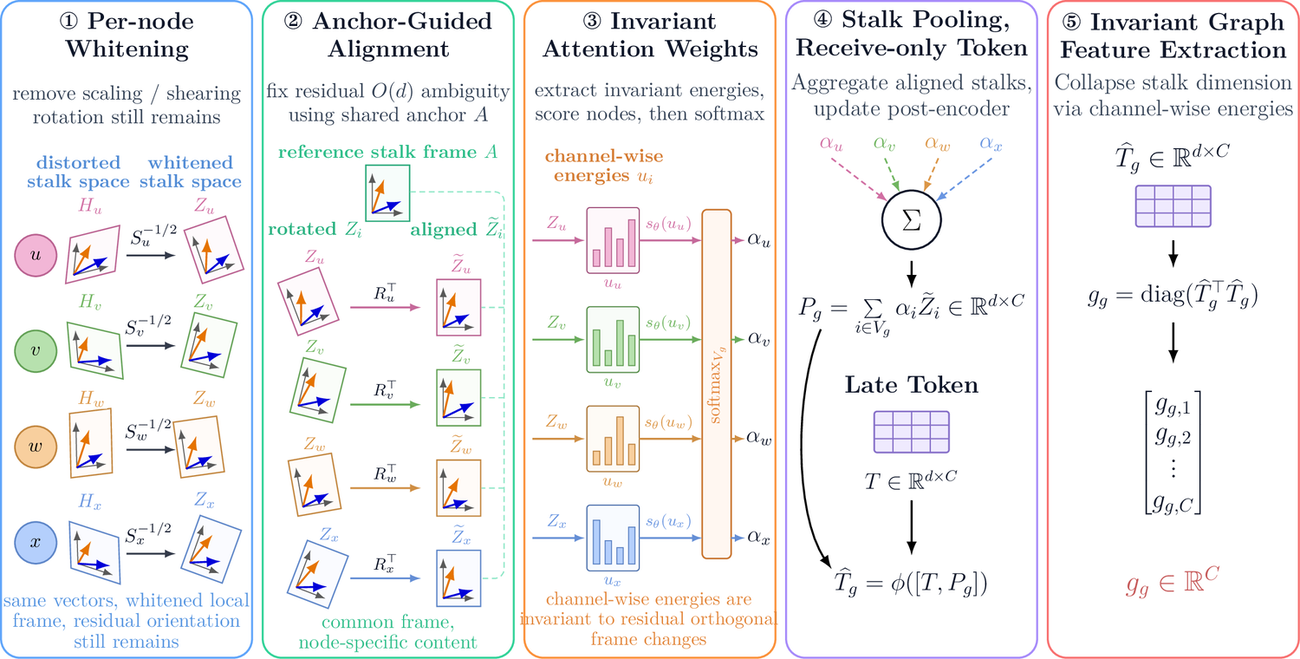

*The SheafPool readout: (1) per-node whitening removes scaling and shearing, (2) anchor alignment resolves residual rotations, (3) invariant attention weights come from stalk energies, (4) aligned stalks are pooled into a late receive-only token, and (5) channel-wise energies give a permutation- and gauge-invariant graph embedding.*

<sub>Source: Braithwaite et al. (2024), *Heterogeneous Sheaf Neural Networks*, [arXiv:2409.08036](https://arxiv.org/abs/2409.08036), Fig. 3. Reproduced for teaching with attribution (CC BY 4.0).</sub>

<a id="9-exercises"></a>
# 9. Configuration, Reproducibility, and Exercises

**Reproducibility.** The seed controls the graph, the features, the splits, and the initialization. Restart the kernel before comparing settings, keep the masks fixed, select on validation loss, and report the test accuracy only once. For real experiments use the repository pipeline (`exp.het_run` or the sweep configs under `configs/<dataset>/het_*`) and record the commit, package versions, seed, predictor family, stalk dimension, depth, and learning rate.

**Key takeaways**
* Heterogeneity (types) and heterophily (labels) are different properties, but relation types often predict whether neighbours agree.
* HetSheaf injects types into the *restriction maps*, so one diffusion model can transport each relation differently.
* Interpreting the maps per relation, together with counterfactual types, shows whether, and how, the model uses the schema.

### Hands-on Exercises
1. **Noise in the schema.** Corrupt 10%, 30%, and 50% of the relation types before training. At what point does HetSheaf-EE fall back to the feature-only accuracy?
2. **Predictor families.** Train every family of Section 3.3 (including NT and ET). Which inputs are necessary on this task, and which are redundant?
3. **Geometry.** Switch to `HetNSDVariant.ORTHOGONAL`. The transport $Q_{v \trianglelefteq e}^{\top}Q_{u \trianglelefteq e}$ is now a rotation. How does the model represent *opposes*? (Hint: in two dimensions $-I$ is the rotation by $\pi$; measure the rotation angle of the transport for each relation.)
4. **Other families.** Replace `HetNSDModel` with `HetSheafAdjModel` or the new `HetDNSDModel`. Does the alignment analysis still separate the two relations?